# ASCIP — Data Exploration & First Forecasting Model

This notebook covers the first ML stage of ASCIP:

1. Load and inspect the supply-chain dataset
2. Clean and prepare dates
3. Perform basic EDA
4. Explore demand over time
5. Select one product-warehouse demand series
6. Split time-series data chronologically
7. Build a naive baseline
8. Create lag and rolling features
9. Train a Random Forest forecasting model
10. Evaluate the model
11. Visualize predictions
12. Detect demand anomalies with Isolation Forest
13. Perform basic supplier-risk analysis

The first forecasting example uses **Laptop (P001) in Delhi**. Later we will generalize the pipeline to all product-warehouse combinations.


## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## 2. Load the raw dataset

In [2]:
DATA_PATH = Path("../data/raw/supply_chain_data.csv")

df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])

df.head()


,date,product_id,product_name,category,warehouse,supplier_id,demand,inventory,order_quantity,delivery_days,defect_rate,supplier_on_time,unit_price,promotion,stockout
0,2025-01-01,P001,Laptop,Electronics,Delhi,S001,191,1286,0,2,0.0190,1,403.72,0,0
1,2025-01-02,P001,Laptop,Electronics,Delhi,S001,189,1097,0,6,0.0210,1,452.52,0,0
2,2025-01-03,P001,Laptop,Electronics,Delhi,S001,218,879,0,4,0.0223,1,450.84,0,0
3,2025-01-04,P001,Laptop,Electronics,Delhi,S001,205,674,0,6,0.0171,1,412.08,0,0
4,2025-01-05,P001,Laptop,Electronics,Delhi,S001,145,529,0,4,0.0189,1,382.19,0,0


In [3]:
print("Shape:", df.shape)
print("Rows:", len(df))
print("Columns:", len(df.columns))


Shape: (36500, 15)
Rows: 36500
Columns: 15


## 3. Basic data inspection

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36500 entries, 0 to 36499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              36500 non-null  datetime64[us]
 1   product_id        36500 non-null  str           
 2   product_name      36500 non-null  str           
 3   category          36500 non-null  str           
 4   warehouse         36500 non-null  str           
 5   supplier_id       36500 non-null  str           
 6   demand            36500 non-null  int64         
 7   inventory         36500 non-null  int64         
 8   order_quantity    36500 non-null  int64         
 9   delivery_days     36500 non-null  int64         
 10  defect_rate       36500 non-null  float64       
 11  supplier_on_time  36500 non-null  int64         
 12  unit_price        36500 non-null  float64       
 13  promotion         36500 non-null  int64         
 14  stockout          36500 non-null 

In [5]:
df.isnull().sum()

date                0
product_id          0
product_name        0
category            0
warehouse           0
supplier_id         0
demand              0
inventory           0
order_quantity      0
delivery_days       0
defect_rate         0
supplier_on_time    0
unit_price          0
promotion           0
stockout            0
dtype: int64

In [6]:
df.describe()

,date,demand,inventory,order_quantity,delivery_days,defect_rate,supplier_on_time,unit_price,promotion,stockout
count,36500,36500.000000,36500.000000,36500.000000,36500.000000,36500.000000,36500.000000,36500.000000,36500.000000,36500.000000
mean,2025-07-02 00:00:00,113.976685,520.262110,130.699068,7.880384,0.033789,0.890986,224.491279,0.092411,0.011781
min,2025-01-01 00:00:00,28.000000,0.000000,0.000000,2.000000,0.000000,0.000000,72.250000,0.000000,0.000000
25%,2025-04-02 00:00:00,69.000000,279.000000,0.000000,6.000000,0.022200,1.000000,90.520000,0.000000,0.000000
50%,2025-07-02 00:00:00,103.000000,441.000000,0.000000,8.000000,0.032200,1.000000,199.545000,0.000000,0.000000
75%,2025-10-01 00:00:00,143.000000,687.000000,0.000000,10.000000,0.045000,1.000000,377.835000,0.000000,0.000000
max,2025-12-31 00:00:00,1109.000000,2198.000000,2317.000000,27.000000,0.094300,1.000000,482.980000,1.000000,1.000000
std,NaN,60.609027,327.146032,302.645143,2.841193,0.015091,0.311661,142.220277,0.289609,0.107900


In [7]:
print("Products:", df["product_id"].nunique())
print("Warehouses:", df["warehouse"].nunique())
print("Suppliers:", df["supplier_id"].nunique())
print("Categories:", df["category"].nunique())

print("\nWarehouses:")
print(df["warehouse"].value_counts())

print("\nSuppliers:")
print(df["supplier_id"].value_counts())


Products: 20
Warehouses: 5
Suppliers: 6
Categories: 6

Warehouses:
warehouse
Delhi        7300
Mumbai       7300
Bangalore    7300
Hyderabad    7300
Pune         7300
Name: count, dtype: int64

Suppliers:
supplier_id
S002    6205
S003    6205
S004    6205
S005    6205
S001    5840
S006    5840
Name: count, dtype: int64


## 4. Total demand by product

In [8]:
product_demand = (
    df.groupby("product_name")["demand"]
    .sum()
    .sort_values(ascending=False)
)

product_demand


product_name
Phone         445664
Laptop        376163
Tablet        314690
PrinterInk    293555
Monitor       275207
Mouse         250745
USBDrive      242237
Router        230660
PowerBank     209569
Keyboard      199500
Smartwatch    189353
Headphones    178391
SSD           157833
Webcam        147112
Printer       136423
Speaker       125472
Chair         114622
Microphone    105229
Desk           93975
Projector      73749
Name: demand, dtype: int64

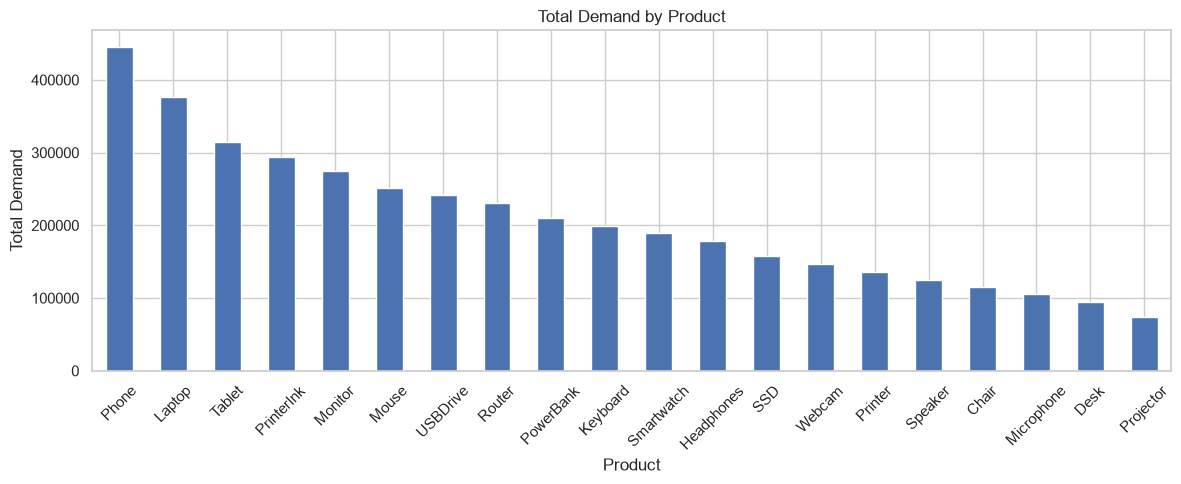

In [9]:
plt.figure(figsize=(12, 5))
product_demand.plot(kind="bar")
plt.title("Total Demand by Product")
plt.xlabel("Product")
plt.ylabel("Total Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 5. Total daily demand

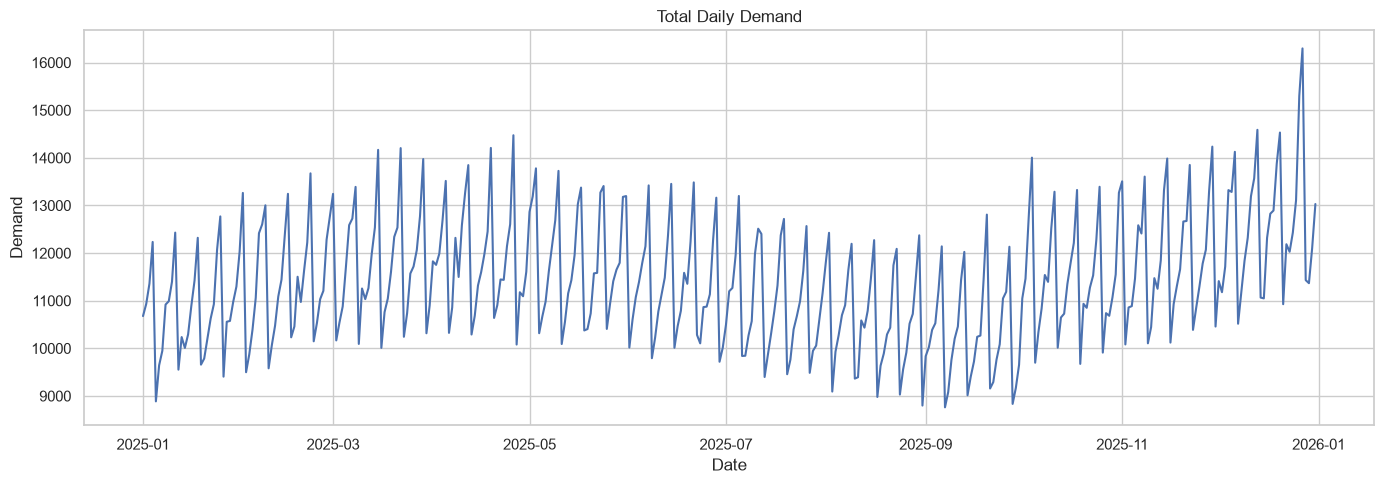

In [10]:
daily_demand = df.groupby("date")["demand"].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_demand.index, daily_demand.values)
plt.title("Total Daily Demand")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()


## 6. Select one product-warehouse series

For the first forecasting model we use Laptop (P001) in Delhi. This gives us one daily time series.


In [11]:
product_data = df[
    (df["product_id"] == "P001") &
    (df["warehouse"] == "Delhi")
].copy()

product_data = product_data.sort_values("date").reset_index(drop=True)

product_data[["date", "product_id", "product_name", "warehouse", "demand", "inventory"]].head()


,date,product_id,product_name,warehouse,demand,inventory
0,2025-01-01,P001,Laptop,Delhi,191,1286
1,2025-01-02,P001,Laptop,Delhi,189,1097
2,2025-01-03,P001,Laptop,Delhi,218,879
3,2025-01-04,P001,Laptop,Delhi,205,674
4,2025-01-05,P001,Laptop,Delhi,145,529


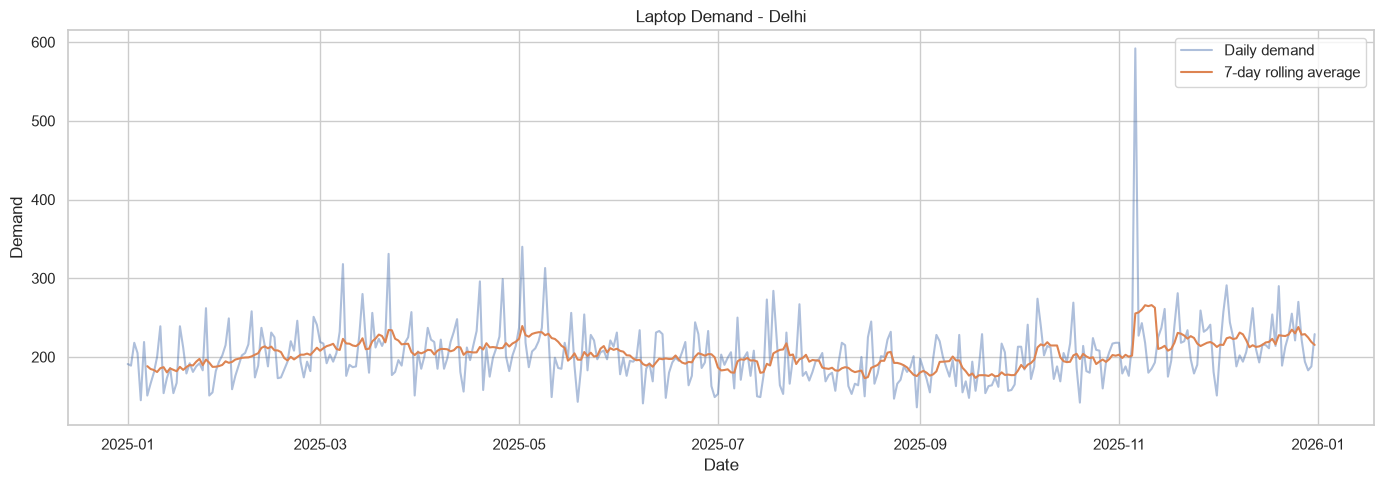

In [12]:
product_data["rolling_7"] = product_data["demand"].rolling(7).mean()

plt.figure(figsize=(14, 5))
plt.plot(product_data["date"], product_data["demand"], alpha=0.45, label="Daily demand")
plt.plot(product_data["date"], product_data["rolling_7"], label="7-day rolling average")
plt.title("Laptop Demand - Delhi")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Time-series train/test split

We preserve chronological order.

- First 80% → training
- Last 20% → testing

We do not randomly shuffle time-series observations.


In [13]:
split = int(len(product_data) * 0.8)

train = product_data.iloc[:split].copy()
test = product_data.iloc[split:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Training period:", train["date"].min(), "to", train["date"].max())
print("Testing period:", test["date"].min(), "to", test["date"].max())


Training rows: 292
Testing rows: 73
Training period: 2025-01-01 00:00:00 to 2025-10-19 00:00:00
Testing period: 2025-10-20 00:00:00 to 2025-12-31 00:00:00


## 8. Baseline forecast

Baseline: tomorrow's demand is predicted as today's demand.

A more complicated model should beat this baseline.


In [14]:
test["baseline_prediction"] = test["demand"].shift(1)
test.loc[test.index[0], "baseline_prediction"] = train["demand"].iloc[-1]

baseline_mae = mean_absolute_error(test["demand"], test["baseline_prediction"])
baseline_rmse = np.sqrt(mean_squared_error(test["demand"], test["baseline_prediction"]))

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))


Baseline MAE: 38.64
Baseline RMSE: 71.14


## 9. Feature engineering

Features use information available before the prediction date:

- lag 1 day
- lag 7 days
- 7-day rolling mean
- 14-day rolling mean
- day of week
- month
- promotion
- inventory

Rolling features are shifted by one day to avoid target leakage.


In [15]:
forecast_df = product_data.copy()

forecast_df["lag_1"] = forecast_df["demand"].shift(1)
forecast_df["lag_7"] = forecast_df["demand"].shift(7)
forecast_df["rolling_7"] = forecast_df["demand"].shift(1).rolling(7).mean()
forecast_df["rolling_14"] = forecast_df["demand"].shift(1).rolling(14).mean()
forecast_df["day_of_week"] = forecast_df["date"].dt.dayofweek
forecast_df["month"] = forecast_df["date"].dt.month

forecast_df = forecast_df.dropna().reset_index(drop=True)

features = [
    "lag_1",
    "lag_7",
    "rolling_7",
    "rolling_14",
    "day_of_week",
    "month",
    "promotion",
    "inventory"
]

target = "demand"

forecast_df[features + [target]].head()


,lag_1,lag_7,rolling_7,rolling_14,day_of_week,month,promotion,inventory,demand
0,186.0,166.0,185.428571,186.857143,2,1,0,927,154
1,154.0,180.0,183.714286,184.214286,3,1,0,760,167
2,167.0,200.0,181.857143,182.642857,4,1,0,521,239
3,239.0,239.0,187.428571,184.142857,5,1,0,1588,212
4,212.0,154.0,183.571429,184.642857,6,1,0,1409,179


## 10. Chronological split for the ML model

In [16]:
split = int(len(forecast_df) * 0.8)

train_ml = forecast_df.iloc[:split].copy()
test_ml = forecast_df.iloc[split:].copy()

X_train = train_ml[features]
y_train = train_ml[target]

X_test = test_ml[features]
y_test = test_ml[target]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train_ml["date"].min(), "to", train_ml["date"].max())
print("Testing period:", test_ml["date"].min(), "to", test_ml["date"].max())


Training rows: 280
Testing rows: 71
Training period: 2025-01-15 00:00:00 to 2025-10-21 00:00:00
Testing period: 2025-10-22 00:00:00 to 2025-12-31 00:00:00


## 11. Train the first ASCIP forecasting model

Random Forest is our first ML model because it can model nonlinear relationships and is easy to inspect.


In [17]:
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)


## 12. Evaluate the forecasting model

In [18]:
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Random Forest")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

print("\nBaseline")
print("MAE :", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))


Random Forest
MAE : 26.1
RMSE: 53.55
R²  : -0.0088

Baseline
MAE : 38.64
RMSE: 71.14


## 13. Actual vs predicted demand

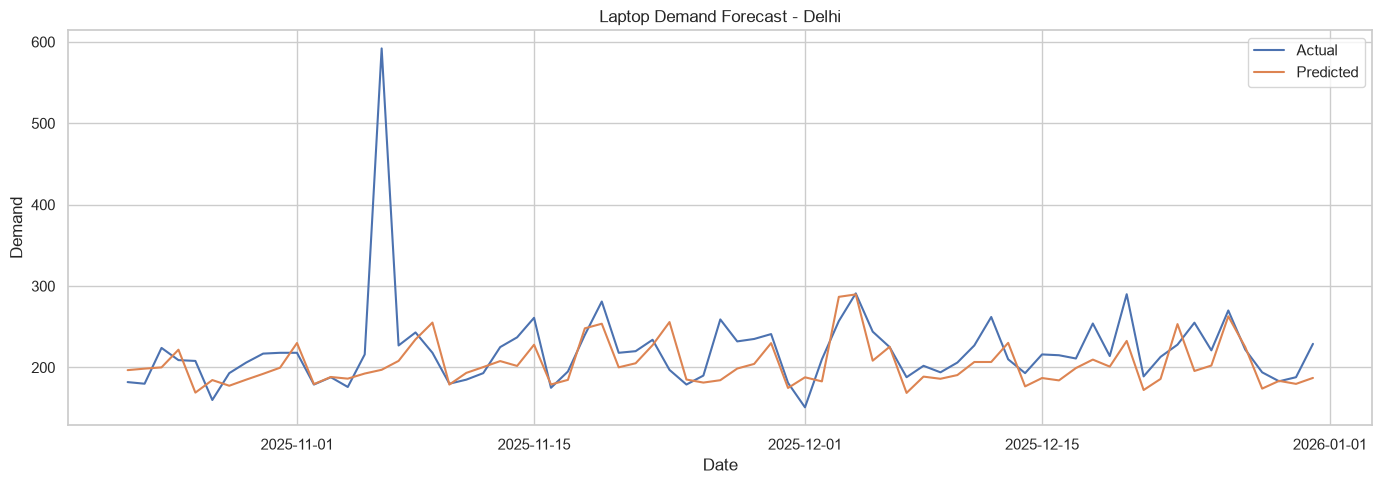

In [19]:
plt.figure(figsize=(14, 5))
plt.plot(test_ml["date"], y_test.values, label="Actual")
plt.plot(test_ml["date"], predictions, label="Predicted")
plt.title("Laptop Demand Forecast - Delhi")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()


## 14. Forecast errors

In [20]:
results = test_ml[["date", "demand"]].copy()
results["prediction"] = predictions
results["error"] = results["demand"] - results["prediction"]
results["absolute_error"] = results["error"].abs()

results.head(10)


,date,demand,prediction,error,absolute_error
280,2025-10-22,182,196.702861,-14.702861,14.702861
281,2025-10-23,180,198.534518,-18.534518,18.534518
282,2025-10-24,224,200.088786,23.911214,23.911214
283,2025-10-25,209,221.796393,-12.796393,12.796393
284,2025-10-26,208,169.062124,38.937876,38.937876
285,2025-10-27,160,184.501665,-24.501665,24.501665
286,2025-10-28,193,177.520704,15.479296,15.479296
287,2025-10-29,206,185.004766,20.995234,20.995234
288,2025-10-30,217,192.153397,24.846603,24.846603
289,2025-10-31,218,199.676275,18.323725,18.323725


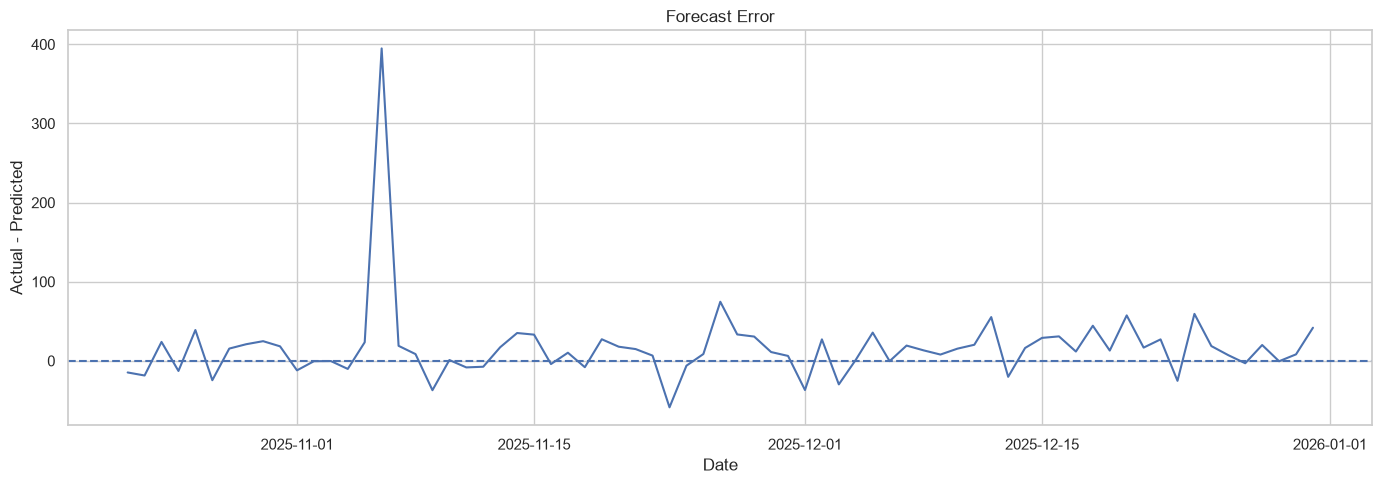

In [21]:
plt.figure(figsize=(14, 5))
plt.plot(results["date"], results["error"])
plt.axhline(0, linestyle="--")
plt.title("Forecast Error")
plt.xlabel("Date")
plt.ylabel("Actual - Predicted")
plt.tight_layout()
plt.show()


## 15. Feature importance

promotion      0.308293
lag_7          0.239349
day_of_week    0.179895
rolling_14     0.065087
lag_1          0.059540
rolling_7      0.053432
month          0.049042
inventory      0.045363
dtype: float64


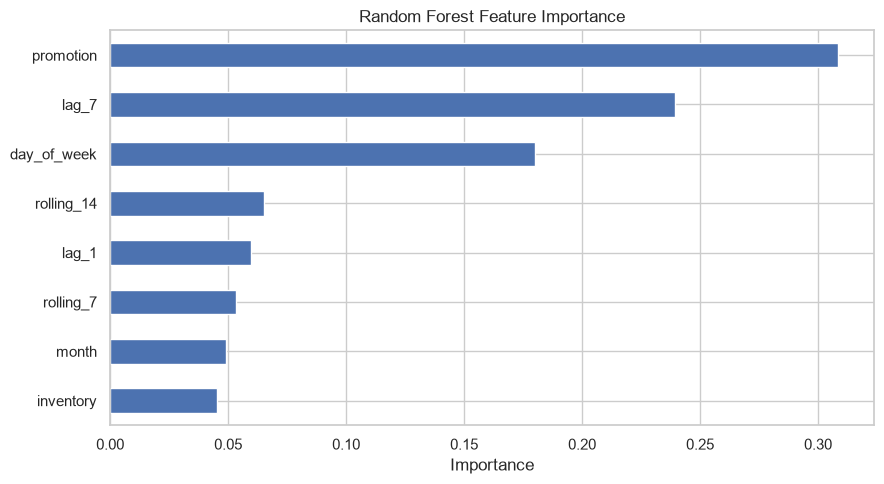

In [22]:
importance = (
    pd.Series(model.feature_importances_, index=features)
    .sort_values(ascending=False)
)

print(importance)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 16. Demand anomaly detection

Isolation Forest identifies observations that are unusual compared with the rest of the data.

For this first demonstration we use demand, inventory, delivery time and defect rate.


In [23]:
anomaly_features = [
    "demand",
    "inventory",
    "delivery_days",
    "defect_rate"
]

anomaly_data = product_data[anomaly_features].copy()

anomaly_model = IsolationForest(
    contamination=0.02,
    random_state=42
)

anomaly_data["anomaly"] = anomaly_model.fit_predict(anomaly_data)
anomaly_data["anomaly"] = anomaly_data["anomaly"].map({1: 0, -1: 1})

product_data["anomaly"] = anomaly_data["anomaly"].values

print("Anomalies detected:", int(product_data["anomaly"].sum()))


Anomalies detected: 8


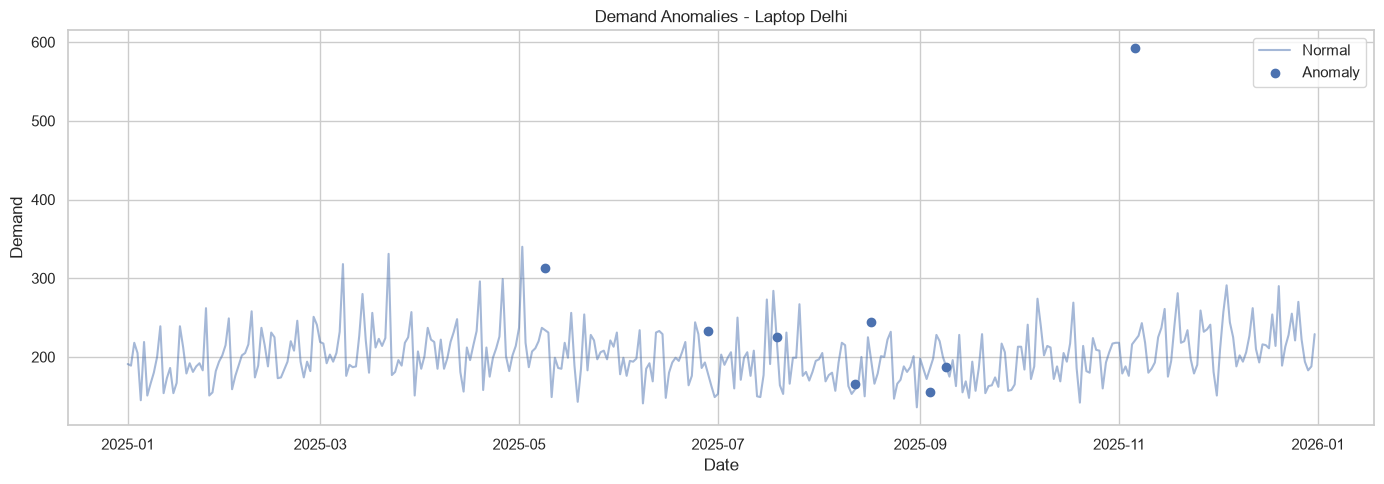

In [24]:
normal = product_data[product_data["anomaly"] == 0]
anomalies = product_data[product_data["anomaly"] == 1]

plt.figure(figsize=(14, 5))
plt.plot(normal["date"], normal["demand"], alpha=0.5, label="Normal")
plt.scatter(anomalies["date"], anomalies["demand"], label="Anomaly", zorder=3)
plt.title("Demand Anomalies - Laptop Delhi")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()


## 17. Supplier risk exploration

In [25]:
supplier_summary = (
    df.groupby("supplier_id")
    .agg(
        avg_delivery_days=("delivery_days", "mean"),
        avg_defect_rate=("defect_rate", "mean"),
        on_time_rate=("supplier_on_time", "mean"),
        total_orders=("order_quantity", lambda x: (x > 0).sum()),
        total_stockouts=("stockout", "sum")
    )
    .sort_values("avg_delivery_days", ascending=False)
)

supplier_summary


,avg_delivery_days,avg_defect_rate,on_time_rate,total_orders,total_stockouts
supplier_id,,,,,
S006,11.232192,0.055182,0.816096,1259,109
S004,9.242063,0.045094,0.859146,1280,99
S005,8.232071,0.034928,0.879936,1232,77
S002,7.174859,0.027912,0.911845,1181,61
S003,6.217083,0.021967,0.932313,1161,38
S001,5.225000,0.017978,0.945377,1084,46


## 18. Save the first forecasting model

In [26]:
import joblib

MODEL_PATH = Path("../models/demand_forecaster.joblib")
joblib.dump(model, MODEL_PATH)

print("Saved:", MODEL_PATH)


Saved: ..\models\demand_forecaster.joblib


## 19. Save processed forecasting data

In [27]:
PROCESSED_PATH = Path("../data/processed/forecasting_data.csv")

forecast_df.to_csv(PROCESSED_PATH, index=False)

print("Saved:", PROCESSED_PATH)


Saved: ..\data\processed\forecasting_data.csv


# What we have achieved

The first ASCIP intelligence layer now contains:

- Data inspection
- Basic EDA
- Demand visualization
- Chronological train/test split
- Naive forecasting baseline
- Lag and rolling features
- Random Forest demand forecasting
- MAE/RMSE/R² evaluation
- Forecast visualization
- Feature importance
- Isolation Forest anomaly detection
- Supplier performance summary
- Saved forecasting model
- Saved processed forecasting data

## Next stage

We will generalize the forecasting pipeline across product-warehouse combinations, then build supplier-risk prediction and SHAP explanations.
